# SteamScope: exploratory data analysis
BANA409 Assignment 4 Part 1 · Team Ryan

## Context and methods
The publishing lead needs price and reception benchmarks for a relevant set of games. This notebook checks the original 2019 Kaggle snapshot before choosing dashboard elements. One row is one application; no causal or current-market conclusions are made.

Source: [Nik Davis, Kaggle](https://www.kaggle.com/datasets/nikdavis/steam-store-games), CC BY 4.0. Downloaded 24 October 2026. Release dates are not price observation dates; prices are GBP. `SOURCE.json` records source identity and the CSV hash.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9,4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
df=pd.read_csv('steam.csv')
df['release_date']=pd.to_datetime(df['release_date'], errors='coerce')
df['year']=df['release_date'].dt.year
df['reviews']=df['positive_ratings']+df['negative_ratings']
df['positive_pct']=df['positive_ratings'].div(df['reviews'].replace(0,float('nan')))*100
print('Rows, original columns:',len(df),18)
print('Release range:',df.release_date.min().date(),df.release_date.max().date())
print('Duplicate app IDs:',df.appid.duplicated().sum())
display(df.head(3))

Rows, original columns: 27075 18
Release range: 1997-06-30 2019-05-01
Duplicate app IDs: 0


,appid,name,release_date,english,developer,publisher,platforms,required_age,categories,genres,...,achievements,positive_ratings,negative_ratings,average_playtime,median_playtime,owners,price,year,reviews,positive_pct
0,10,Counter-Strike,2000-11-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,...,0,124534,3339,17612,317,10000000-20000000,7.19,2000,127873,97.388815
1,20,Team Fortress Classic,1999-04-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Online Multi-Player;Local Multi-P...,Action,...,0,3318,633,277,62,5000000-10000000,3.99,1999,3951,83.978740
2,30,Day of Defeat,2003-05-01,1,Valve,Valve,windows;mac;linux,0,Multi-player;Valve Anti-Cheat enabled,Action,...,0,3416,398,187,34,5000000-10000000,3.99,2003,3814,89.564761


## Data quality

In [2]:
quality=pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum()})
display(quality)
display(df[['price','reviews','positive_pct','average_playtime']].describe().round(2))
print('Zero-review games:',(df.reviews==0).sum())
print('Free games:',(df.price==0).sum())
assert len(df)==27075 and not df.appid.duplicated().any()
assert (df.price>=0).all() and (df.reviews>=0).all()
assert df.positive_pct.dropna().between(0,100).all()

,dtype,missing
appid,int64,0
name,str,0
release_date,datetime64[us],0
english,int64,0
developer,str,1
publisher,str,14
platforms,str,0
required_age,int64,0
categories,str,0
genres,str,0


,price,reviews,positive_pct,average_playtime
count,27075.00,27075.00,27075.00,27075.00
mean,6.08,1211.59,71.45,149.80
std,7.87,22429.09,23.36,1827.04
min,0.00,1.00,0.00,0.00
25%,1.69,10.00,58.33,0.00
50%,3.99,36.00,76.03,0.00
75%,7.19,176.00,89.39,0.00
max,421.99,3046717.00,100.00,190625.00


Zero-review games: 0
Free games: 2560


## Distributions

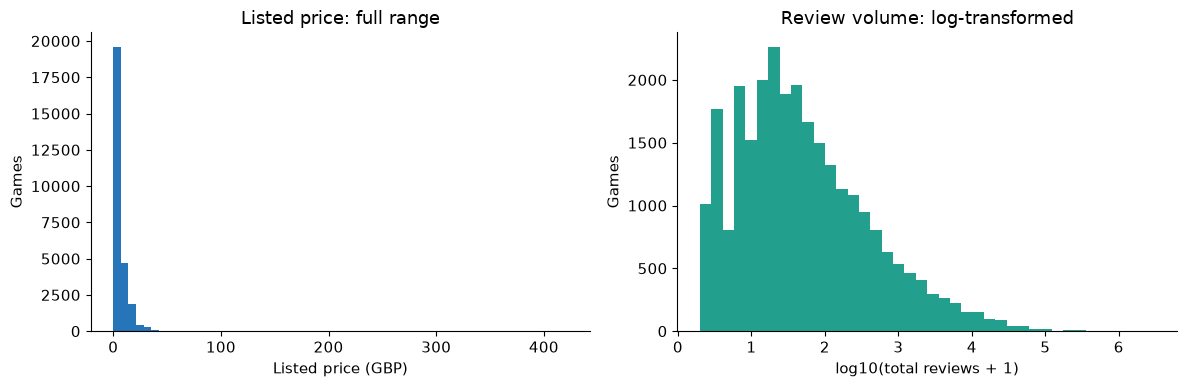

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
df.price.plot.hist(bins=60,ax=ax[0],color='#2675b8')
ax[0].set(title='Listed price: full range',xlabel='Listed price (GBP)',ylabel='Games')
import numpy as np
ax[1].hist(np.log10(df.reviews+1),bins=40,color='#23a08d')
ax[1].set(title='Review volume: log-transformed',xlabel='log10(total reviews + 1)',ylabel='Games')
fig.tight_layout()
plt.show()

The long price and review-volume tails make means sensitive to a small set of games. The dashboard uses medians, separates free games, and allows a minimum-review threshold. The transformed review histogram includes zero-review games.

## Default peer group and relationships

Games                          4172.00
Median price (GBP)                5.19
Median positive reviews (%)      80.00
dtype: float64

,games,median_price,median_positive_pct
year,,,
2016,1509,4.79,77.92
2017,1450,4.99,79.03
2018,1213,7.19,83.39


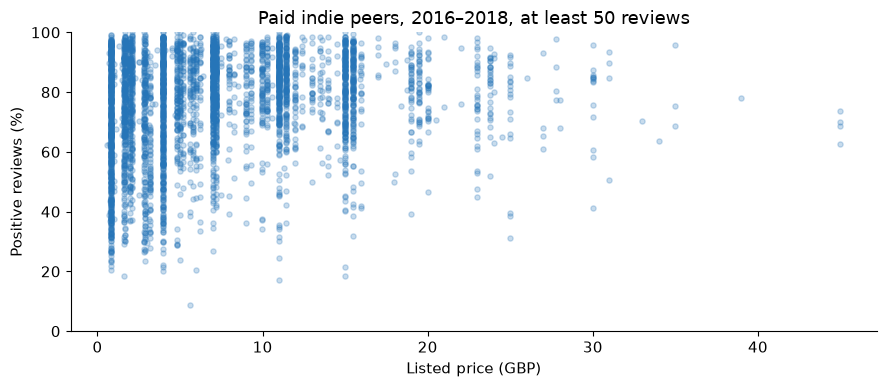

Spearman price/reception association: 0.215


In [4]:
peer=df.loc[df.genres.str.split(';').apply(lambda x:'Indie' in x) & df.year.between(2016,2018) & (df.price>0) & (df.reviews>=50)].copy()
display(pd.Series({'Games':len(peer),'Median price (GBP)':peer.price.median(),'Median positive reviews (%)':peer.positive_pct.median()}).round(2))
display(peer.groupby('year').agg(games=('appid','size'), median_price=('price','median'), median_positive_pct=('positive_pct','median')).round(2))
fig,ax=plt.subplots()
ax.scatter(peer.price,peer.positive_pct,s=14,alpha=.25,color='#2675b8')
ax.set(title='Paid indie peers, 2016–2018, at least 50 reviews',xlabel='Listed price (GBP)',ylabel='Positive reviews (%)',ylim=(0,100))
fig.tight_layout()
plt.show()
print('Spearman price/reception association:',round(peer[['price','positive_pct']].corr(method='spearman').iloc[0,1],3))

## Takeaways and dashboard choices
Price alone does not determine player reception; the scatter is observational and does not estimate the effect of charging more. Use a price-band distribution and a reception-by-release-cohort chart to inspect peers, with the same filters feeding every KPI and chart. Do not interpret release-cohort differences as changes in ratings over calendar time. The default excludes 2019 because that year is incomplete. Avoid revenue estimates from owners ranges and listed prices; actual transactions and costs are unavailable. The README contains the full decision and refresh rationale.